# Public Reactions to the Men's 100m Final at the Paris 2024 Olympic Games

*Module 6: Telling the Game: NLP for Sports Intelligence — MSc in AI Applied to Sports*

## Introduction

The men's 100m final at the Paris 2024 Olympic Games provides a focused context for examining how online audiences discuss a major sporting event. YouTube comments offer a source of public reactions, including expressions of enthusiasm, criticism, and observations about the race. Analysing this language can help explore how spectators interpret and respond to elite sporting performances.

This project will examine English-language YouTube comments using exactly two natural language processing (NLP) techniques: word frequency analysis of bigrams and trigrams, and sentiment analysis with positive, negative, and neutral categories. Together, these techniques will describe recurring expressions and the sentiment conveyed in the selected comments. The analysis will concern the sampled YouTube discussion; it will not represent all spectators or establish commenters' underlying intentions.

This notebook currently presents the research plan and local API key configuration only. No comments have been collected or analysed, and no results are reported.

## Research Question and Objectives

**Research question:** What recurring bigrams and trigrams and what distribution of positive, negative, and neutral sentiment characterise the selected English-language YouTube comments about the men's 100m final at Paris 2024?

The project will pursue the following objectives:

1. Define and document a sample of English-language comments from YouTube videos directly related to the final.
2. Identify and rank the most frequent bigrams and trigrams in the prepared comment text.
3. Classify comments as positive, negative, or neutral and summarise the distribution of these categories.
4. Interpret the descriptive outputs in relation to the sporting context, acknowledging sampling limitations and challenges such as sarcasm and ambiguous language.

## Proposed Data and Methodology

**Data source.** The proposed dataset will consist of publicly available English-language comments on selected YouTube videos covering the men's 100m final at Paris 2024. Video selection, collection method, collection date, sample size, and inclusion criteria will be documented when data collection is undertaken. The sample may be influenced by the videos selected, comment availability, and the collection period.

**Technique 1: Word Frequency Analysis.** Bigrams (two consecutive words) and trigrams (three consecutive words) will be counted and ranked to identify recurring expressions. Text preparation decisions will be documented before analysis to make their effects on the counts transparent. Frequent expressions will be interpreted in context rather than treated as evidence of audience-wide opinions.

**Technique 2: Sentiment Analysis.** Each included comment will be assigned a positive, negative, or neutral label using a method to be selected and justified during implementation. The analysis will summarise these labels while recognising that mixed sentiment, sarcasm, and sports-specific language may complicate classification.

**Expected visualizations.** Separate horizontal bar charts will display the most frequent bigrams and trigrams. A further bar chart will show the number and percentage of comments in each sentiment category. These are planned outputs, not observed findings.

## Local API Key Configuration

Copy `.env.example` to `.env` in the project directory and replace `your_api_key_here` with your YouTube Data API v3 key. Keep `.env` private; it is excluded from Git. The selected notebook environment must have `python-dotenv` installed. Run the notebook with the project directory as its working directory. The cell below loads the local key and checks that it is configured without displaying it or calling the API.

In [ ]:
import os
from dotenv import load_dotenv

load_dotenv(dotenv_path=".env")
YOUTUBE_API_KEY = os.getenv("YOUTUBE_API_KEY")

if not YOUTUBE_API_KEY or not YOUTUBE_API_KEY.strip() or YOUTUBE_API_KEY.strip() == "your_api_key_here":
    raise ValueError("Configure YOUTUBE_API_KEY in your local .env file before continuing.")

print("YouTube API key is configured.")

## Data Source Validation

Before collecting the dataset, this test will verify that the selected video is accessible through the YouTube Data API v3 and that top-level comments are available. Video metadata and a small sample of up to 10 comments will help assess whether the source is suitable for subsequent collection. Comments are requested in relevance order, so this sample is not representative of the full discussion. Their language is not assumed to be English; language eligibility will be assessed in a later stage. The reported comment count, when available, is a video-level statistic and may include replies, whereas this test retrieves only top-level comments. This step performs no NLP analysis.


In [2]:
import requests

VIDEO_ID = "7Xnr805bm4E"
API_BASE = "https://www.googleapis.com/youtube/v3"


def youtube_get(resource, **params):
    """Return API data or a safe diagnostic without exposing request URLs."""
    try:
        response = requests.get(
            f"{API_BASE}/{resource}",
            params={**params, "key": YOUTUBE_API_KEY},
            timeout=30,
        )
    except requests.RequestException:
        print(f"{resource}: network request failed (connection or timeout).")
        return None

    try:
        data = response.json()
    except ValueError:
        print(f"{resource}: invalid JSON response (HTTP {response.status_code}).")
        return None

    if not response.ok or "error" in data:
        # Use structured reason codes only; raw errors may include credentials.
        reasons = [
            error.get("reason", "unknown")
            for error in data.get("error", {}).get("errors", [])
        ]
        if "commentsDisabled" in reasons:
            print("Comments are disabled for this video.")
        else:
            reason = ", ".join(reasons) or "unspecified API error"
            print(f"{resource}: HTTP {response.status_code}; reason: {reason}")
        return None
    return data


video_data = youtube_get("videos", part="snippet,statistics", id=VIDEO_ID)
if video_data is not None:
    videos = video_data.get("items", [])
    if not videos:
        print("No accessible video was returned for the supplied video ID.")
    else:
        video = videos[0]
        snippet = video.get("snippet", {})
        print("Title:", snippet.get("title", "Unavailable"))
        print("Channel:", snippet.get("channelTitle", "Unavailable"))
        print("Publication date:", snippet.get("publishedAt", "Unavailable"))
        print("Available comment count:", video.get("statistics", {}).get("commentCount", "Unavailable"))

        comment_data = youtube_get(
            "commentThreads",
            part="snippet",
            videoId=VIDEO_ID,
            maxResults=10,
            textFormat="plainText",
            order="relevance",
        )
        if comment_data is not None:
            comments = comment_data.get("items", [])[:10]
            print(f"Top-level comments returned: {len(comments)}")
            if not comments:
                print("No top-level comments were returned.")
            for number, item in enumerate(comments, start=1):
                text = item.get("snippet", {}).get("topLevelComment", {}).get("snippet", {}).get("textDisplay", "")
                preview = text if len(text) <= 150 else text[:147] + "..."
                print(f"{number}. {preview}")


Title: Men's 100m Final | Paris Champions
Channel: Olympic Games
Publication date: 2024-08-12T00:00:02Z
Available comment count: 2546
Top-level comments returned: 10
1. The best of the #Paris2024 athletics action  https://oly.ch/P24Athletics
2. you do a 15min video of a 9 second race and 3 minute videos of 1 hour basketball games.
3. Without Bolt we can finally see how close a 100m final can be
4. Imagine running 9.91 and getting last place...
5. the 100 m is such a bloodsport. the guy coming in last clocks 9.91. just crazy
6. This race produced fastest 4th, 5th, 6th, 7th and 8th places ever in 100m history 🔥🔥⚡⚡🥇
7. This Olympics goes on to show just how great Bolt was. Noah won 100m, but couldn't win 200m and didn't participate in the 4x100m relay. Jacobs who ...
8. Bolt sitting at home laughing
9. last place got 9.92. Crazy
10. Imagine what's like to think you're leading the race until the finish line, then finding out that for MERE 0.004 SECONDS you got silver medal. That...


## Data Collection

Top-level comments will be collected from the validated Olympic Games video, `7Xnr805bm4E`, using the YouTube Data API v3 and the existing API helper. Requests will retrieve pages of up to 100 comments in time order, following `nextPageToken` until 1,000 unique comments have been collected or no further pages are available. Duplicate comment IDs will be excluded. The CSV will retain each comment's ID, video ID, original plain-text content, publication timestamp, and like count; replies will not be collected.

Selection is limited to comments accessible through the API at collection time. No language filtering or text cleaning will be applied at this stage, so the dataset may contain multiple languages. Time ordering and the collection cap favour recently posted comments, while deleted, moderated, or otherwise unavailable comments cannot be included. The sample therefore does not represent all viewers or the complete historical discussion. API failures may result in a partial dataset, which will be identified in the collection output. Rerunning the cell will replace `comments.csv` with the new collection.


In [3]:
import csv
import json
from datetime import datetime, timezone

MAX_COMMENTS = 1000
fields = ["comment_id", "video_id", "text", "published_at", "like_count"]
collected_comments = []
seen_ids = set()
duplicate_count = 0
page_token = None
used_page_tokens = set()
collection_status = "Comment limit reached."
collection_started_at = datetime.now(timezone.utc).isoformat()

while len(collected_comments) < MAX_COMMENTS:
    params = {
        "part": "snippet",
        "videoId": VIDEO_ID,
        "maxResults": 100,
        "order": "time",
        "textFormat": "plainText",
    }
    if page_token:
        params["pageToken"] = page_token

    page = youtube_get("commentThreads", **params)
    if page is None:
        collection_status = "Stopped after an API/network error; any collected data are partial."
        break

    items = page.get("items", [])
    if not items:
        collection_status = "No further comments were returned."
        break

    for item in items:
        comment = item["snippet"]["topLevelComment"]
        comment_id = comment["id"]
        if comment_id in seen_ids:
            duplicate_count += 1
            continue
        seen_ids.add(comment_id)
        snippet = comment["snippet"]
        collected_comments.append({
            "comment_id": comment_id,
            "video_id": VIDEO_ID,
            "text": snippet["textDisplay"],
            "published_at": snippet["publishedAt"],
            "like_count": snippet.get("likeCount", 0),
        })
        if len(collected_comments) == MAX_COMMENTS:
            break

    if len(collected_comments) == MAX_COMMENTS:
        break
    page_token = page.get("nextPageToken")
    if not page_token:
        collection_status = "All available pages were retrieved."
        break
    if page_token in used_page_tokens:
        collection_status = "Stopped because the API repeated a page token; data may be partial."
        break
    used_page_tokens.add(page_token)

print("Collection started (UTC):", collection_started_at)
print("Collection status:", collection_status)
print("Unique top-level comments collected:", len(collected_comments))
print("Duplicate comment IDs excluded:", duplicate_count)
if collected_comments:
    dates = [datetime.fromisoformat(row["published_at"].replace("Z", "+00:00"))
             for row in collected_comments]
    print("Publication date range (UTC):", min(dates).isoformat(), "to", max(dates).isoformat())
    with open("comments.csv", "w", newline="", encoding="utf-8") as csv_file:
        writer = csv.DictWriter(csv_file, fieldnames=fields)
        writer.writeheader()
        writer.writerows(collected_comments)
    print("Saved to comments.csv")
    print("Preview of five records:")
    print(json.dumps(collected_comments[:5], ensure_ascii=False, indent=2))
else:
    print("Publication date range: unavailable (no comments collected).")
    print("No CSV written because no comments were collected.")


Collection started (UTC): 2026-10-30T14:38:59.757272+00:00
Collection status: Comment limit reached.
Unique top-level comments collected: 1000
Duplicate comment IDs excluded: 1
Publication date range (UTC): 2024-08-12T10:27:44+00:00 to 2026-10-24T18:03:08+00:00
Saved to comments.csv
Preview of five records:
[
  {
    "comment_id": "Ugxm-aUys1sQRvOr68l4AaABAg",
    "video_id": "7Xnr805bm4E",
    "text": "The best of the #Paris2024 athletics action  https://oly.ch/P24Athletics",
    "published_at": "2024-08-15T14:54:42Z",
    "like_count": 179
  },
  {
    "comment_id": "UgzpFU_lFIA5RkM9pjJ4AaABAg",
    "video_id": "7Xnr805bm4E",
    "text": "6:45",
    "published_at": "2026-10-24T18:03:08Z",
    "like_count": 0
  },
  {
    "comment_id": "UgzCG0cBsfcv8PJ97l14AaABAg",
    "video_id": "7Xnr805bm4E",
    "text": "3:09 This is the most main character moment in sports history",
    "published_at": "2026-10-06T13:58:19Z",
    "like_count": 0
  },
  {
    "comment_id": "Ugy0LUs8Et8NFWY6NZl4AaA

## Dataset Quality Assessment

Language distribution and text quality must be assessed before preprocessing because multilingual, missing, or low-content comments may affect the interpretation of subsequent frequency and sentiment results. This assessment reads the existing CSV without contacting YouTube and retains every record and its original text. Character and whitespace-delimited word lengths describe the raw comments; these are descriptive measures rather than linguistic tokenisation.

Language is estimated using the lightweight [langdetect library](https://pypi.org/project/langdetect/) (`langdetect==1.0.9`), with a fixed seed of 0. Short texts are particularly ambiguous. Comments with fewer than 20 alphabetic characters, failed detections, or a top detector score below 0.90 are labelled `unknown`. These pragmatic thresholds are not validated accuracy guarantees, and detector scores are not calibrated probabilities of correctness. Mixed-language comments may receive only one label. Manual inspection is therefore necessary before selecting English-language material.

Diagnostic flags identify timestamp-only text (one or more `m:ss` or `h:mm:ss` references), link-only text (`http://`, `https://`, or `www.`), and very little textual content (fewer than 10 alphabetic characters). Counts may overlap. Temporary removal of links for the last diagnostic count does not change stored text or the text submitted for detection. All assessment variables remain in memory; no comments are removed, cleaned, or written back to disk. The notebook environment requires pandas, matplotlib, and langdetect.


Dataset shape (rows, columns): (1000, 5)
Missing values by column:


,missing_values
comment_id,0
video_id,0
text,0
published_at,0
like_count,0


Duplicate comment IDs (beyond first occurrence): 0
Comment length distribution (non-missing text only):


,characters,whitespace_words
count,1000.00,1000.00
mean,57.12,10.51
std,64.05,11.57
min,1.00,1.00
25%,22.75,4.00
50%,41.00,8.00
75%,71.00,13.00
90%,114.00,21.00
95%,153.05,29.00
max,1032.00,176.00


Low-content diagnostics (overlapping counts):


,comments
timestamp_only,14
link_only,0
fewer_than_10_letters_excluding_links,114
any_of_these_flags,114


Estimated language distribution (ISO language codes):


,count,percentage
language,,
en,602,60.2
unknown,335,33.5
es,14,1.4
ru,14,1.4
id,10,1.0
fr,4,0.4
vi,4,0.4
th,2,0.2
pt,2,0.2


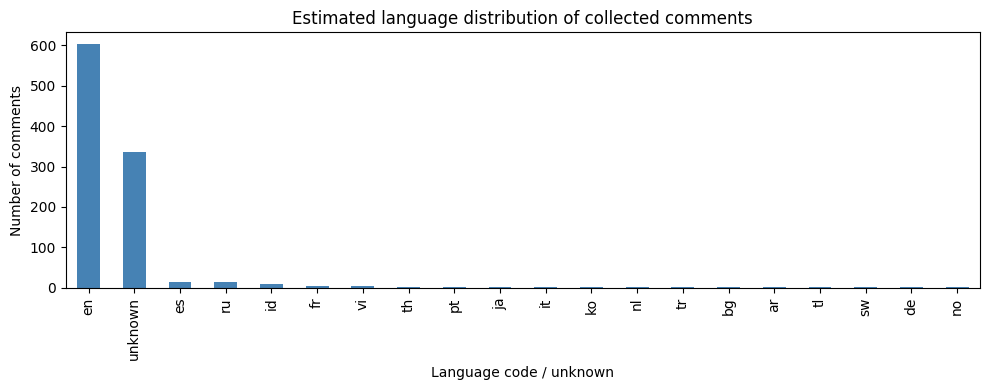

English: 602 comments; up to three reproducible examples


,comment_id,text,estimated_language
498,UgyuqvxOXc7GUxpNiG94AaABAg,Who else was watching 👀 Kerley's print 😳,en
93,Ugw3jwLZiR8TG7YdThV4AaABAg,"The ""first"" and the ""second"" Same time, so... Same medal.... !?! 🤔",en
822,UgzmXrVgM0Ou7yO-L0d4AaABAg,Why India is not begging for gold medal in this race ?? They deserve it .... Kumar ran very fast ......,en


Non-English: 63 comments; up to three reproducible examples


,comment_id,text,estimated_language
644,UgybGKQeFakOzMjrIF54AaABAg,لم أشاهد فوز ظالم وغير مستحق مثل هذا في حياتي,ar
710,Ugztzg-zu3eRDKLw3zN4AaABAg,"Q mal acostumbrados nos dejo Bold, horita estás carreras son parejas. En la era de Bold ganaba sobrado",es
993,Ugz0R-o2OAnbt_8zAjZ4AaABAg,all finalist take under 10 sec,no


Unknown: 335 comments; up to three reproducible examples


,comment_id,text,estimated_language
435,Ugy4PgjI7G3q1faRAKN4AaABAg,Lyles as charisma like bolt.\nVery confident,unknown
209,Ugwbdbv3RiNDFrZZx6B4AaABAg,Who knows Ishow speed ??,unknown
29,Ugwq9y3yf7tGp75TyaZ4AaABAg,฿ 0:24,unknown


In [4]:
import re
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from langdetect import DetectorFactory, detect_langs, LangDetectException

DetectorFactory.seed = 0
comments_df = pd.read_csv("comments.csv", dtype={"comment_id": "string", "video_id": "string", "text": "string"})
quality_text = comments_df["text"].fillna("")
print("Dataset shape (rows, columns):", comments_df.shape)
print("Missing values by column:")
display(comments_df.isna().sum().rename("missing_values").to_frame())
print("Duplicate comment IDs (beyond first occurrence):", int(comments_df["comment_id"].dropna().duplicated().sum()))

lengths = pd.DataFrame({
    "characters": quality_text.str.len(),
    "whitespace_words": quality_text.str.split().str.len(),
})
print("Comment length distribution (non-missing text only):")
display(lengths.loc[comments_df["text"].notna()].astype(float).describe(percentiles=[0.25, 0.5, 0.75, 0.90, 0.95]).round(2))

link_pattern = r"(?:https?://|www\.)\S+"
time_pattern = r"(?:\d+:)?\d{1,3}:[0-5]\d"
timestamp_only = quality_text.str.fullmatch(rf"\s*{time_pattern}(?:\s+{time_pattern})*\s*")
link_only = quality_text.str.fullmatch(rf"\s*{link_pattern}(?:\s+{link_pattern})*\s*", flags=re.IGNORECASE)
very_little_text = quality_text.map(lambda text: sum(c.isalpha() for c in re.sub(link_pattern, "", text, flags=re.IGNORECASE)) < 10)
print("Low-content diagnostics (overlapping counts):")
display(pd.Series({
    "timestamp_only": int(timestamp_only.sum()),
    "link_only": int(link_only.sum()),
    "fewer_than_10_letters_excluding_links": int(very_little_text.sum()),
    "any_of_these_flags": int((timestamp_only | link_only | very_little_text).sum()),
}).rename("comments").to_frame())


def estimate_language(text):
    if sum(c.isalpha() for c in text) < 20:
        return "unknown"
    try:
        predictions = detect_langs(text)
        if predictions and predictions[0].prob >= 0.90:
            return predictions[0].lang
    except LangDetectException:
        pass
    return "unknown"


language_labels = quality_text.map(estimate_language)
language_distribution = language_labels.value_counts().rename_axis("language").to_frame("count")
language_distribution["percentage"] = (100 * language_distribution["count"] / len(comments_df)).round(1)
print("Estimated language distribution (ISO language codes):")
display(language_distribution)

fig, ax = plt.subplots(figsize=(10, 4))
language_distribution["count"].plot.bar(ax=ax, color="steelblue")
ax.set(title="Estimated language distribution of collected comments", xlabel="Language code / unknown", ylabel="Number of comments")
fig.tight_layout()
plt.show()

sample_groups = {
    "English": language_labels.eq("en"),
    "Non-English": ~language_labels.isin(["en", "unknown"]),
    "Unknown": language_labels.eq("unknown"),
}
for group, mask in sample_groups.items():
    print(f"{group}: {int(mask.sum())} comments; up to three reproducible examples")
    sample = comments_df.loc[mask, ["comment_id", "text"]].copy()
    sample["estimated_language"] = language_labels.loc[mask]
    if sample.empty:
        print("No comments in this category.")
    else:
        with pd.option_context("display.max_colwidth", None):
            display(sample.sample(n=min(3, len(sample)), random_state=0))


## Language Filtering and Sample Selection

Sample selection reuses `comments_df` and the initial `language_labels` without changing either. Timestamp-only and link-only comments are excluded first. A further exclusion applies to comments containing fewer than 10 alphabetic letters after URLs, timestamp references, and standalone numbers are removed from a temporary diagnostic string. This minimum is a methodological choice intended to retain interpretable language, not a validated boundary between useful and unusable comments.

Initially detected English comments meeting the content criterion are retained. Unknown comments are reassessed without the previous 20-letter gate. Recovery requires both an English detector score of at least 0.99 and at least two distinct words from an explicit English grammatical-cue list, including at least one of the stronger structural cues listed in the code. Matching is case-insensitive and uses whole words; Latin script, athlete names, or sporting terms alone do not qualify. The same rule applies to short and longer unknown comments. Previously detected non-English comments are excluded rather than relabelled.

This deliberately restrictive rule may miss valid English comments. Grammatical cues can occur in other languages or quotations, while detector scores are not calibrated accuracy estimates; recovered labels remain provisional, especially for mixed-language text. Samples are displayed for review, with no manual relabelling or translation. Diagnostic strings and word matches are used only for selection: `analysis_df` preserves the original text and metadata. Exclusion reasons are mutually exclusive and assigned in the order shown below, so each comment contributes to exactly one selection outcome. No preprocessing or additional substantive NLP analysis is performed.


In [5]:
# Run Dataset Quality Assessment first; no API calls are needed.
import re
import pandas as pd
from IPython.display import display
from langdetect import DetectorFactory, detect_langs, LangDetectException

DetectorFactory.seed = 0
selection_text = comments_df["text"].fillna("")
url_rule = r"(?:https?://|www\.)\S+"
timestamp_rule = r"(?<!\w)(?:\d+:)?\d{1,3}:[0-5]\d(?!\w)"


def diagnostic_content(text):
    value = re.sub(url_rule, " ", text, flags=re.IGNORECASE)
    value = re.sub(timestamp_rule, " ", value)
    return re.sub(r"\b\d+(?:[.,]\d+)*\b", " ", value)


content_for_selection = selection_text.map(diagnostic_content)
alphabetic_count = content_for_selection.map(lambda text: sum(c.isalpha() for c in text))
only_timestamps = selection_text.str.fullmatch(r"\s*(?:\d+:)?\d{1,3}:[0-5]\d(?:\s+(?:\d+:)?\d{1,3}:[0-5]\d)*\s*")
only_links = selection_text.str.fullmatch(rf"\s*{url_rule}(?:\s+{url_rule})*\s*", flags=re.IGNORECASE)

# Fixed linguistic cues, not labels assigned to individual comments.
english_cues = set("the this that what with without was were is are he his they you your it how but and not of to in for on a an".split())
structural_cues = set("the this that what with without was were are your they his how".split())


def recover_unknown_english(text):
    words = set(re.findall(r"\b[a-z]+\b", text.casefold()))
    if len(words & english_cues) < 2 or not (words & structural_cues):
        return False
    try:
        predictions = detect_langs(text)
        return bool(predictions and predictions[0].lang == "en" and predictions[0].prob >= 0.99)
    except LangDetectException:
        return False


selection_reason = pd.Series("excluded: unresolved language", index=comments_df.index, dtype="string")
recovered_english = pd.Series(False, index=comments_df.index)
for index in comments_df.index:
    if only_timestamps.loc[index]:
        selection_reason.loc[index] = "excluded: timestamp only"
    elif only_links.loc[index]:
        selection_reason.loc[index] = "excluded: link only"
    elif alphabetic_count.loc[index] < 10:
        selection_reason.loc[index] = "excluded: fewer than 10 letters"
    elif language_labels.loc[index] == "en":
        selection_reason.loc[index] = "retained: initially detected English"
    elif language_labels.loc[index] != "unknown":
        selection_reason.loc[index] = "excluded: initially detected non-English"
    elif recover_unknown_english(content_for_selection.loc[index]):
        recovered_english.loc[index] = True
        selection_reason.loc[index] = "retained: recovered unknown English"

retained_mask = selection_reason.str.startswith("retained:")
analysis_df = comments_df.loc[retained_mask].copy()
print("Original comments:", len(comments_df))
print("Retained:", len(analysis_df))
print("Excluded:", int((~retained_mask).sum()))
reason_order = [
    "retained: initially detected English",
    "retained: recovered unknown English",
    "excluded: timestamp only",
    "excluded: link only",
    "excluded: fewer than 10 letters",
    "excluded: initially detected non-English",
    "excluded: unresolved language",
]
selection_summary = selection_reason.value_counts().reindex(reason_order, fill_value=0).to_frame("comments")
selection_summary["percentage"] = (selection_summary["comments"] / len(comments_df) * 100).round(1)
display(selection_summary)

short_unknown = selection_text.map(lambda text: sum(c.isalpha() for c in text)).lt(20)
print("Recovered unknown comments with fewer than 20 original alphabetic letters:", int((recovered_english & short_unknown).sum()))
review_masks = {
    "Recovered short English comments": recovered_english & short_unknown,
    "Excluded comments (up to one example per reason)": ~retained_mask,
}
for title, mask in review_masks.items():
    print(title)
    review = comments_df.loc[mask, ["comment_id", "text"]].copy()
    review["initial_language"] = language_labels.loc[mask]
    review["selection_reason"] = selection_reason.loc[mask]
    if review.empty:
        print("No comments meet these criteria.")
    else:
        if title.startswith("Excluded"):
            review = review.groupby("selection_reason", sort=True).head(1)
        else:
            review = review.sample(n=min(5, len(review)), random_state=0)
        with pd.option_context("display.max_colwidth", None):
            display(review)

assert len(analysis_df) + int((~retained_mask).sum()) == len(comments_df)
assert analysis_df.equals(comments_df.loc[retained_mask])


Original comments: 1000
Retained: 618
Excluded: 382


,comments,percentage
retained: initially detected English,602,60.2
retained: recovered unknown English,16,1.6
excluded: timestamp only,14,1.4
excluded: link only,0,0.0
excluded: fewer than 10 letters,100,10.0
excluded: initially detected non-English,63,6.3
excluded: unresolved language,205,20.5


Recovered unknown comments with fewer than 20 original alphabetic letters: 16
Recovered short English comments


,comment_id,text,initial_language,selection_reason
156,UgzQGJ9AJ43mEKB-Irt4AaABAg,That replay at 11:39 is super.,unknown,retained: recovered unknown English
669,UgznOUjKn0IfQmRItVp4AaABAg,Champion of what?,unknown,retained: recovered unknown English
745,Ugxd_vp6o7bcgUZI8bt4AaABAg,World champion of what ?,unknown,retained: recovered unknown English
747,UgwMO3HjRAwcFlbS1x94AaABAg,J.A. was robbed,unknown,retained: recovered unknown English
825,Ugx6JJ7RSW2u9FWQOBl4AaABAg,World champion of what 🎉🎉🎉,unknown,retained: recovered unknown English


Excluded comments (up to one example per reason)


,comment_id,text,initial_language,selection_reason
1,UgzpFU_lFIA5RkM9pjJ4AaABAg,6:45,unknown,excluded: timestamp only
5,UgzMCQHra_pwajFL2qd4AaABAg,1st floor and home,unknown,excluded: unresolved language
12,Ugyv8mF3ob8KzYlRJ9h4AaABAg,Lyle’s couldn’t done 9.59 seconds,fr,excluded: initially detected non-English
23,UgwtwxQSkxkwuesV5B14AaABAg,Nice,unknown,excluded: fewer than 10 letters


## Text Preprocessing

Preprocessing is applied specifically to the selected comments for N-gram frequency analysis. A new `clean_text` column will contain the processed text, while the original `text` and metadata remain intact for later sentiment analysis, where punctuation, case, and emojis may convey meaning. No rows are removed, including comments that become empty.

Text is lowercased, and URLs, timestamp references, and standalone numbers are removed. Common negative contractions are expanded to preserve `not`; other common apostrophe endings are discarded before tokenisation. A regular expression extracts contiguous Unicode alphabetic words, excluding digits, punctuation, underscores, and emojis. Tokens are filtered using [scikit-learn's built-in English stopword list](https://github.com/scikit-learn/scikit-learn/blob/main/sklearn/feature_extraction/_stop_words.py), with `no`, `not`, `never`, `nor`, and `against` explicitly retained. Joining the remaining words with single spaces eliminates empty tokens and excess whitespace. The notebook environment requires scikit-learn.

No stemming or lemmatisation is used, preserving surface word forms and keeping the procedure transparent; related forms will therefore remain separate in later counts. Removing stopwords and punctuation can create adjacency between words that were not consecutive in the original text, so later N-grams must be interpreted as sequences in the processed representation rather than verbatim phrases.


In [6]:
import re
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

retained_words = {"no", "not", "never", "nor", "against"}
ngram_stopwords = set(ENGLISH_STOP_WORDS) - retained_words


def preprocess_for_ngrams(text):
    text = text.lower()
    text = re.sub(r"(?:https?://|www\.)\S+", " ", text)
    text = re.sub(r"(?<!\w)(?:\d+:)?\d{1,3}:[0-5]\d(?!\w)", " ", text)
    text = re.sub(r"\b\d+(?:[.,]\d+)*\b", " ", text)
    # Preserve negation before punctuation is discarded.
    text = text.replace("’", "'")
    text = re.sub(r"\bcan't\b", "can not", text)
    text = re.sub(r"\bwon't\b", "will not", text)
    text = re.sub(r"\bshan't\b", "shall not", text)
    text = re.sub(r"n't\b", " not", text)
    text = re.sub(r"'(?:s|re|ve|ll|d|m)\b", " ", text)
    tokens = re.findall(r"[^\W\d_]+", text, flags=re.UNICODE)
    return " ".join(token for token in tokens if token and token not in ngram_stopwords)


original_analysis_text = analysis_df["text"].copy(deep=True)
analysis_df["clean_text"] = analysis_df["text"].fillna("").map(preprocess_for_ngrams)
empty_after_cleaning = analysis_df["clean_text"].eq("")
print("Comments retained (no rows removed):", len(analysis_df))
print("Comments empty after cleaning:", int(empty_after_cleaning.sum()))
print("Five original-versus-cleaned examples (fixed random seed):")
with pd.option_context("display.max_colwidth", None):
    display(analysis_df[["text", "clean_text"]].sample(n=min(5, len(analysis_df)), random_state=0))
assert analysis_df["text"].equals(original_analysis_text)


Comments retained (no rows removed): 618
Comments empty after cleaning: 0
Five original-versus-cleaned examples (fixed random seed):


,text,clean_text
784,"Once brought as slaves and now they are making america better, .",brought slaves making america better
770,Please upload full videos of gymnastics finals.... individual and team......please 🥺,upload videos gymnastics finals individual team
377,Thompson really had the gold though but ok,thompson really gold ok
718,Biggest scam of the tournament. Organizer and Jury let him win just because US need a champion. Fact is THOMPSON the one first that reach the final line,biggest scam tournament organizer jury let win just need champion fact thompson reach final line
604,it's pretty amazing how athletes train themselves for such event and the margin between victory is so small,pretty amazing athletes train event margin victory small


## N-gram Frequency Analysis

Bigrams and trigrams are sequences of two and three adjacent tokens, respectively. Their frequencies describe recurring word combinations within the selected English-language comments. This analysis uses the whitespace-separated tokens in `analysis_df["clean_text"]`, preserving their order within each comment. Sliding windows generate sequences separately for each comment, and a counter sums all occurrences across comments; repeated occurrences within a comment are counted. No sequence crosses comment boundaries.

Because stopwords and punctuation were removed during preprocessing, some adjacent token pairs or triples were not consecutive in the original text. The outputs therefore describe combinations in the processed representation rather than necessarily verbatim phrases. The top 15 sequences of each length are presented in tables and horizontal bar charts. Ties are ordered alphabetically for reproducibility. These descriptive counts do not measure sentiment or establish the prevalence of opinions among all viewers.


Selected comments analysed: 618
Top 15 bigrams (occurrence counts):


,ngram,frequency
0,usain bolt,27
1,noah lyles,23
2,won race,11
3,kishane thompson,10
4,world champion,10
5,did not,9
6,does not,9
7,gold medal,9
8,thompson won,8
9,won gold,8


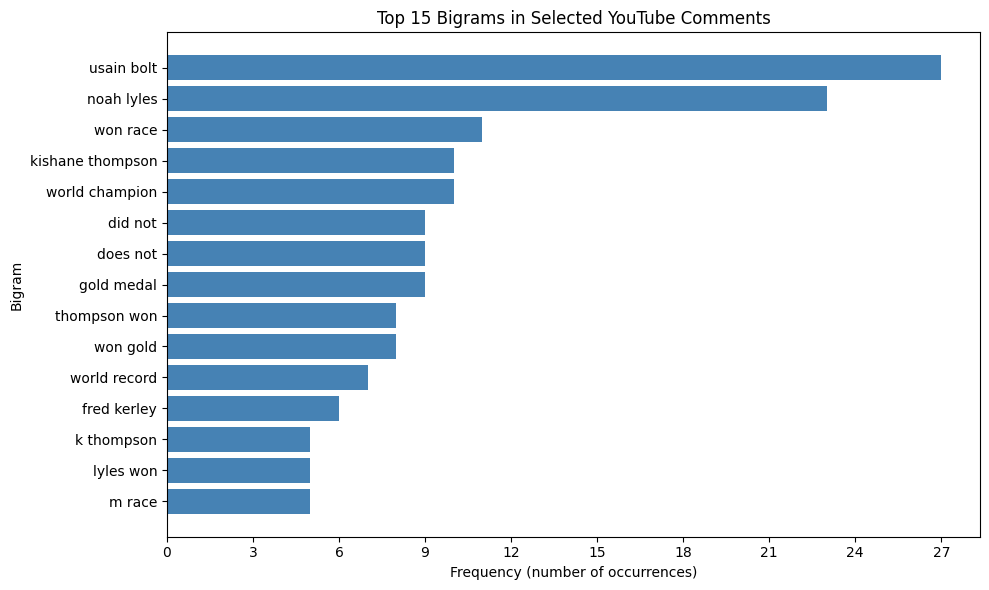

Top 15 trigrams (occurrence counts):


,ngram,frequency
0,africa not usa,3
1,s speed km,3
2,speed km h,3
3,th th th,3
4,bednarek went early,2
5,best olympic final,2
6,comments usain bolt,2
7,crowd gets jacobs,2
8,did not win,2
9,does not iq,2


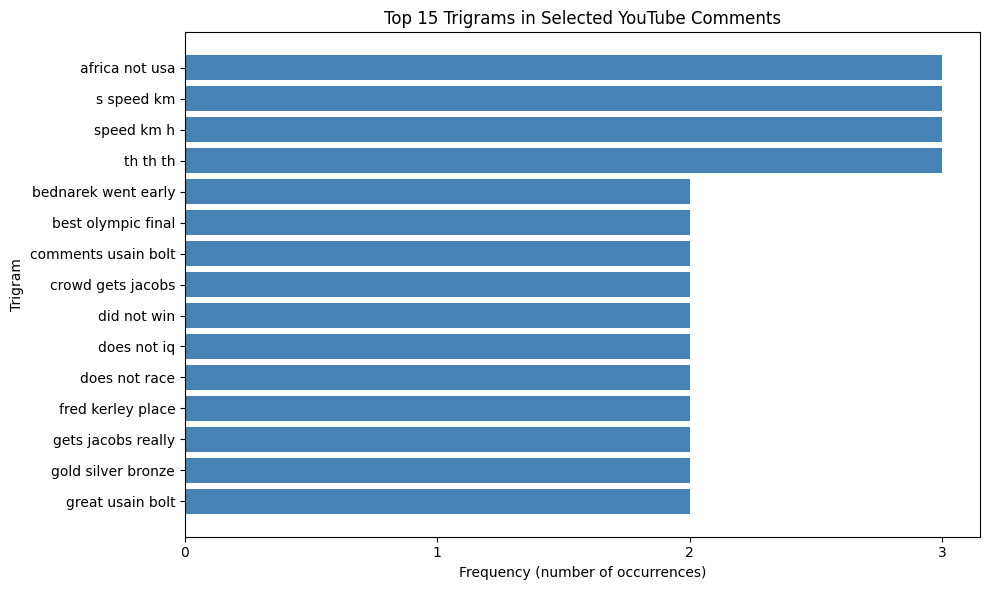

In [7]:
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


def count_ngrams(texts, size):
    counts = Counter()
    for text in texts:
        tokens = text.split()
        counts.update(tuple(tokens[start:start + size])
                      for start in range(len(tokens) - size + 1))
    return counts


bigram_counts = count_ngrams(analysis_df["clean_text"], 2)
trigram_counts = count_ngrams(analysis_df["clean_text"], 3)


def top_ngram_table(counts, limit=15):
    ranked = sorted(counts.items(), key=lambda item: (-item[1], item[0]))[:limit]
    return pd.DataFrame([(" ".join(tokens), frequency) for tokens, frequency in ranked],
                        columns=["ngram", "frequency"])


top_bigrams = top_ngram_table(bigram_counts)
top_trigrams = top_ngram_table(trigram_counts)
print("Selected comments analysed:", len(analysis_df))
for label, table in [("Bigrams", top_bigrams), ("Trigrams", top_trigrams)]:
    print(f"Top 15 {label.lower()} (occurrence counts):")
    display(table)
    if table.empty:
        print(f"No {label.lower()} available.")
        continue
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(table["ngram"], table["frequency"], color="steelblue")
    ax.invert_yaxis()
    ax.set_title(f"Top 15 {label} in Selected YouTube Comments")
    ax.set_xlabel("Frequency (number of occurrences)")
    ax.set_ylabel(label[:-1])
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    fig.tight_layout()
    plt.show()


### Results Summary

Across 618 selected comments, the most frequent processed bigram was **usain bolt** (27 occurrences), followed by **noah lyles** (23). Four processed trigrams shared the highest frequency of 3 occurrences: **africa not usa**, **s speed km**, **speed km h**, and **th th th**. The remaining displayed trigrams each occurred twice. Some leading trigrams contain fragments or units, illustrating limitations of the current preprocessing. These are occurrence counts, not counts of distinct commenters or measures of sentiment. The tables report the 15 highest-ranked combinations for each sequence length, with alphabetical ordering used to resolve ties.
